# `Customer Churn Prediction`
**PRD:** Week 3 · Days 14–15 · §24.2 · FR-07, FR-08 · User Story 3 (top-10 churn drivers + risk list for Growth Marketing)

**Definition.** A customer has *churned* if they place **no order in the 60 days after a snapshot date**. Features use only history up to the snapshot, so nothing from the future leaks in.

**Class imbalance.** Most customers do not reorder within 60 days, so churn is the majority class. We use balanced class weights and report ROC-AUC / PR-AUC beside F1, because F1 for the majority class is trivially high.

In [1]:
import sys, warnings
sys.path.insert(0, '../src'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import model_churn as mc
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', palette='deep'); IMG = Path('../images')
abt = pd.read_csv('../data/cleaned/analytical_base_table.csv', parse_dates=['OrderDate'])
cust = pd.read_csv('../data/cleaned/customers.csv')
S = mc.build_snapshot(abt, cust)
T = S.attrs['snapshot']
print(f'Snapshot date T = {T:%d %b %Y}; label window = next {mc.HORIZON_DAYS} days (to {abt.OrderDate.max():%d %b %Y})')
print(f'Customers active on/before T: {len(S):,} | churned: {S.churn_60d.mean():.1%} | retained: {1 - S.churn_60d.mean():.1%}')

Snapshot date T = 01 Nov 2024; label window = next 60 days (to 31 Dec 2024)
Customers active on/before T: 9,488 | churned: 87.2% | retained: 12.8%

## 1 · Feature table (leakage-free, as of the snapshot)

In [2]:
S[mc.NUMERIC + mc.CATEGORICAL + ['churn_60d']].describe(include='all').T.round(2).head(20)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
recency_days,9488.0,NaN,NaN,NaN,251.9707,182.828736,0.0,95.0,217.0,386.0,670.0
frequency,9488.0,NaN,NaN,NaN,1.98398,1.081459,1.0,1.0,2.0,3.0,8.0
monetary,9488.0,NaN,NaN,NaN,516.003631,427.874755,0.0,212.8125,446.3,750.3625,3055.7
avg_order_value,9488.0,NaN,NaN,NaN,391.995796,131.812419,33.0,303.6625,386.35,472.05,976.3
late_rate,9488.0,NaN,NaN,NaN,0.104916,0.246547,0.0,0.0,0.0,0.0,1.0
cancel_rate,9488.0,NaN,NaN,NaN,0.221731,0.334709,0.0,0.0,0.0,0.5,1.0
not_delivered_rate,9488.0,NaN,NaN,NaN,0.116872,0.260375,0.0,0.0,0.0,0.0,1.0
avg_delivery_time,9488.0,NaN,NaN,NaN,36.689139,11.112352,8.0,30.0,35.5,42.0,99.0
coupon_rate,9488.0,NaN,NaN,NaN,0.354864,0.387104,0.0,0.0,0.333333,0.6,1.0
avg_rating,9488.0,NaN,NaN,NaN,3.544133,0.999211,1.0,3.0,3.666667,4.333333,5.0


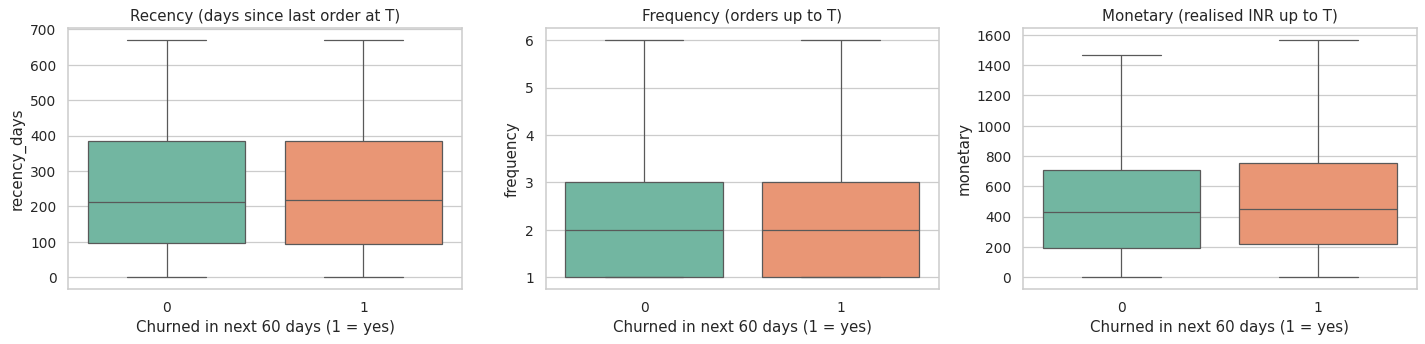

,recency_days,frequency,monetary,orders_last_90d
churn_60d,,,,
0,251.68,1.94,497.45,0.25
1,252.01,1.99,518.72,0.27


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, ttl in zip(axes, ['recency_days', 'frequency', 'monetary'], ['Recency (days since last order at T)', 'Frequency (orders up to T)', 'Monetary (realised INR up to T)']):
    sns.boxplot(data=S, x='churn_60d', y=col, ax=ax, showfliers=False, palette='Set2'); ax.set_title(ttl); ax.set_xlabel('Churned in next 60 days (1 = yes)'); ax.set_ylabel(col)
plt.tight_layout(); plt.savefig(IMG / '05_rfm_by_churn.png', dpi=110)
S.groupby('churn_60d')[['recency_days', 'frequency', 'monetary', 'orders_last_90d']].mean().round(2)

The retained and churned groups look almost identical on recency, frequency and spend. In real subscription-like businesses these separate sharply; here they do not. Expect a weak model.

## 2 · Split, train and compare 4 algorithms + baseline (FR-07)

In [4]:
X_train, X_test, y_train, y_test = mc.split(S)
print(f'train {len(X_train):,} (churn {y_train.mean():.1%}) | test {len(X_test):,} (churn {y_test.mean():.1%}) - stratified')
results, fitted, probas = mc.compare_models(X_train, y_train, X_test, y_test)
results.round(3)

train 7,590 (churn 87.2%) | test 1,898 (churn 87.2%) - stratified

,Model,CV_ROC_AUC,Accuracy,Precision,Recall,F1,Macro_F1,ROC_AUC,PR_AUC
0,Baseline (always churn),NaN,0.872,0.872,1.000,0.932,0.466,0.500,0.872
1,Logistic Regression,0.518,0.522,0.858,0.542,0.664,0.417,0.471,0.862
2,Decision Tree,0.520,0.327,0.890,0.260,0.403,0.316,0.539,0.885
3,Random Forest,0.525,0.803,0.871,0.910,0.890,0.489,0.506,0.875
4,Gradient Boosting,0.515,0.602,0.879,0.630,0.734,0.470,0.529,0.878


**How to read this table.** `F1`, `Precision`, `Recall` are for the *churn* class at a 0.5 threshold. The **baseline that always says 'churn'** gets F1 ≈ 0.93 with zero insight, so the PRD's 'F1 ≥ 0.70' is satisfied by doing nothing. The honest measure of skill is **ROC-AUC** (0.5 = coin flip) and **PR-AUC compared with the churn prevalence**.

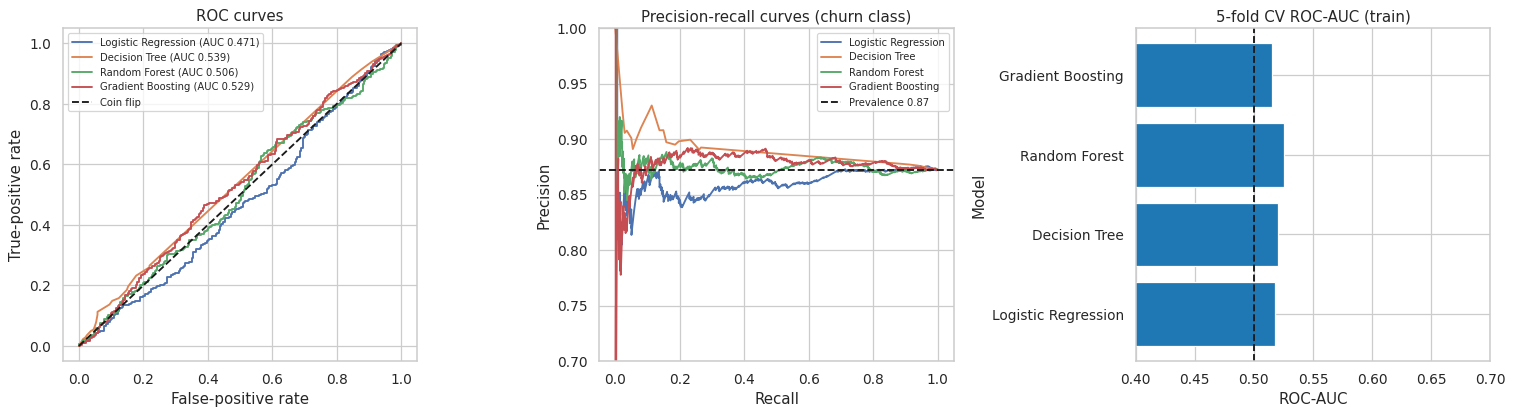

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); models = [k for k in probas if not k.startswith('Baseline')]
for k in models:
    fpr, tpr, _ = roc_curve(y_test, probas[k]); axes[0].plot(fpr, tpr, label=f'{k} (AUC {roc_auc_score(y_test, probas[k]):.3f})')
    p, r, _ = precision_recall_curve(y_test, probas[k]); axes[1].plot(r, p, label=k)
axes[0].plot([0, 1], [0, 1], 'k--', label='Coin flip'); axes[0].set_title('ROC curves'); axes[0].set_xlabel('False-positive rate'); axes[0].set_ylabel('True-positive rate'); axes[0].legend(fontsize=8)
axes[1].axhline(y_test.mean(), color='k', ls='--', label=f'Prevalence {y_test.mean():.2f}'); axes[1].set_title('Precision-recall curves (churn class)'); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_ylim(.7, 1); axes[1].legend(fontsize=8)
r_ = results[~results.Model.str.startswith('Baseline')]; axes[2].barh(r_.Model, r_.CV_ROC_AUC, color='tab:blue'); axes[2].axvline(.5, color='k', ls='--'); axes[2].set_xlim(.4, .7); axes[2].set_title('5-fold CV ROC-AUC (train)'); axes[2].set_xlabel('ROC-AUC'); axes[2].set_ylabel('Model')
plt.tight_layout(); plt.savefig(IMG / '05_roc_pr_comparison.png', dpi=110)

## 3 · Select, tune, evaluate

In [6]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
best_name = results[~results.Model.str.startswith('Baseline')].sort_values('CV_ROC_AUC', ascending=False).iloc[0].Model
print('Best by CV ROC-AUC:', best_name)
spaces = {'Random Forest': {'m__n_estimators': [150, 300], 'm__max_depth': [3, 5, 8], 'm__min_samples_leaf': [20, 50, 100]},
          'Gradient Boosting': {'m__n_estimators': [80, 150], 'm__max_depth': [2, 3], 'm__learning_rate': [.02, .05], 'm__min_samples_leaf': [30, 80]},
          'Logistic Regression': {'m__C': [.01, .1, 1, 10]}, 'Decision Tree': {'m__max_depth': [2, 3, 5], 'm__min_samples_leaf': [50, 100, 200]}}
s = RandomizedSearchCV(mc.candidate_models()[best_name], spaces[best_name], n_iter=4, cv=StratifiedKFold(3, shuffle=True, random_state=42), scoring='roc_auc', random_state=42)
s.fit(X_train, y_train) if best_name != 'Gradient Boosting' else s.fit(X_train, y_train, m__sample_weight=mc.compute_sample_weight('balanced', y_train))
final_pipe = s.best_estimator_; proba = final_pipe.predict_proba(X_test)[:, 1]
tuned = mc.classification_metrics(y_test, proba)
print(f'tuned CV AUC {s.best_score_:.3f} | params {s.best_params_}'); pd.Series(tuned).round(3).to_frame('tuned model on test set')

Best by CV ROC-AUC: Random Forest
tuned CV AUC 0.523 | params {'m__n_estimators': 150, 'm__min_samples_leaf': 50, 'm__max_depth': 5}

,tuned model on test set
Accuracy,0.656
Precision,0.870
Recall,0.713
F1,0.783
Macro_F1,0.475
ROC_AUC,0.501
PR_AUC,0.875


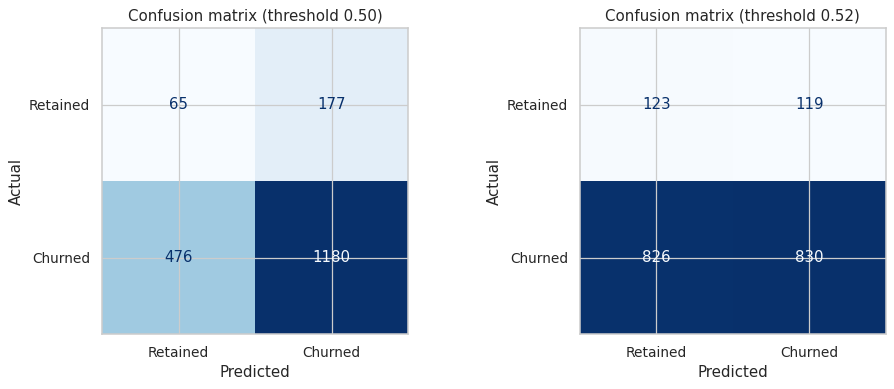

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, thr in zip(axes, [0.5, np.median(proba)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, proba >= thr), display_labels=['Retained', 'Churned']).plot(ax=ax, colorbar=False, cmap='Blues'); ax.set_title(f'Confusion matrix (threshold {thr:.2f})'); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.savefig(IMG / '05_confusion_matrices.png', dpi=110)

In [8]:
# Is the AUC distinguishable from chance?  Permutation test on the labels (NumPy)
rng = np.random.default_rng(42); yt = y_test.to_numpy(); obs = roc_auc_score(yt, proba)
null = np.array([roc_auc_score(rng.permutation(yt), proba) for _ in range(500)])
print(f'Observed test AUC {obs:.3f} | null mean {null.mean():.3f} (sd {null.std():.3f}) | permutation p-value {(null >= obs).mean():.3f}')

Observed test AUC 0.501 | null mean 0.500 (sd 0.020) | permutation p-value 0.484

## 4 · Top-10 churn drivers (User Story 3)

In [9]:
top = mc.top_features(final_pipe, X_test, y_test, n=10); top.round(4)

,feature,auc_drop_when_shuffled,std
0,age,0.0154,0.0055
1,recency_days,0.0068,0.0044
2,late_rate,0.0038,0.0022
3,orders_last_90d,0.0016,0.0007
4,avg_delivery_time,0.0009,0.0063
5,n_restaurants,0.0004,0.0012
6,frequency,0.0002,0.0016
7,not_delivered_rate,-0.0000,0.0013
8,avg_order_value,-0.0001,0.0082
9,cancel_rate,-0.0010,0.0018


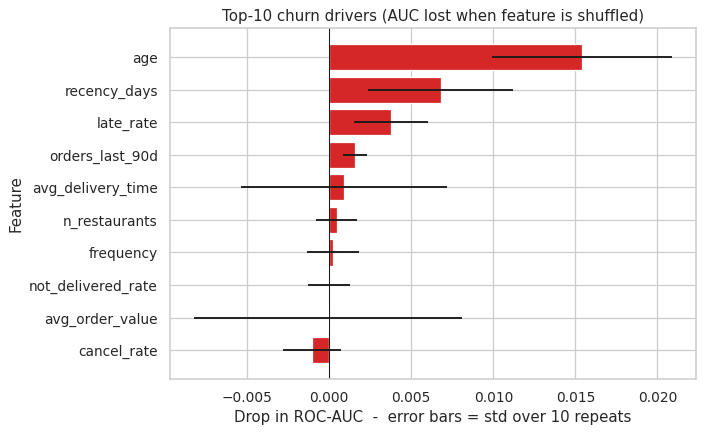

In [10]:
fig, ax = plt.subplots(figsize=(8, 5)); t = top.iloc[::-1]; ax.barh(t.feature, t.auc_drop_when_shuffled, xerr=t['std'], color='tab:red')
ax.axvline(0, color='k', lw=.8); ax.set_title('Top-10 churn drivers (AUC lost when feature is shuffled)'); ax.set_xlabel('Drop in ROC-AUC  -  error bars = std over 10 repeats'); ax.set_ylabel('Feature')
plt.tight_layout(); plt.savefig(IMG / '05_churn_drivers.png', dpi=110); top.to_csv('../reports/churn_top_drivers.csv', index=False)

## 5 · Churn-risk list for Growth Marketing
Even with weak discrimination, the output format Marketing asked for is produced: every active customer gets a probability and a band. Treat the ranking as **indicative only**.

In [11]:
scored = S.copy(); scored['churn_probability'] = final_pipe.predict_proba(S[mc.NUMERIC + mc.CATEGORICAL])[:, 1]
scored['risk_band'] = pd.qcut(scored.churn_probability.rank(method='first'), 3, labels=['Low risk', 'Medium risk', 'High risk'])
out = scored.reset_index()[['CustomerID', 'churn_probability', 'risk_band', 'recency_days', 'frequency', 'monetary', 'membership']].sort_values('churn_probability', ascending=False)
out.to_csv('../reports/churn_risk_scores.csv', index=False)
print(f'Scored {len(out):,} customers -> reports/churn_risk_scores.csv (includes training customers, so in-sample)')
# Honest validation of the bands: HOLD-OUT customers only
held = scored.loc[X_test.index]
held.groupby('risk_band').churn_60d.agg(customers='count', actual_churn_rate='mean').round(3)

Scored 9,488 customers -> reports/churn_risk_scores.csv (includes training customers, so in-sample)

,customers,actual_churn_rate
risk_band,,
Low risk,601,0.882
Medium risk,686,0.863
High risk,611,0.874


On **hold-out customers only**, a model with skill would show actual churn rising steadily from Low to High risk. Compare the rates above: any gap is small and unstable (AUC ≈ 0.5). The same table computed on all customers looks better only because the model has already seen the training customers. (Bands are terciles of the score, not fixed thresholds.)

## 6 · Robustness check: rolling snapshots (temporal split)

In [12]:
# Train on snapshots up to mid-2024, test on later ones: does anything generalise over time?
snaps = pd.concat([mc.build_snapshot(abt, cust, t).assign(T=pd.Timestamp(t)) for t in pd.date_range('2023-04-01', '2024-11-01', freq='MS')])
tr, te = snaps[snaps['T'] < '2024-06-01'], snaps[snaps['T'] >= '2024-08-01']
from sklearn.ensemble import GradientBoostingClassifier
cols = mc.NUMERIC
gb = GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=.05, random_state=42).fit(tr[cols], tr.churn_60d)
print(f'rolling snapshots: {len(snaps):,} customer-snapshots | temporal-test AUC {roc_auc_score(te.churn_60d, gb.predict_proba(te[cols])[:, 1]):.3f} (0.5 = chance)')

rolling snapshots: 133,186 customer-snapshots | temporal-test AUC 0.493 (0.5 = chance)

## 7 · PRD KPI check, conclusions and recommendations

In [13]:
always = results[results.Model.str.startswith('Baseline')].iloc[0]
pd.DataFrame([{'KPI': 'F1 (churn class) >= 0.70', 'Tuned model': round(tuned['F1'], 3), 'Always-churn baseline': round(always.F1, 3), 'Nominally met': tuned['F1'] >= .7, 'Meaningful': False},
              {'KPI': 'ROC-AUC (skill beyond chance)', 'Tuned model': round(tuned['ROC_AUC'], 3), 'Always-churn baseline': 0.5, 'Nominally met': None, 'Meaningful': tuned['ROC_AUC'] >= .65}])

,KPI,Tuned model,Always-churn baseline,Nominally met,Meaningful
0,F1 (churn class) >= 0.70,0.783,0.932,True,False
1,ROC-AUC (skill beyond chance),0.501,0.500,None,False


### Conclusions
* **F1 ≥ 0.70 is nominally met but not meaningful.** Predicting 'churn' for everyone scores F1 ≈ 0.93. The metric that measures real skill, **ROC-AUC, is ≈ 0.5**, and a permutation test cannot distinguish it from chance. The same holds on rolling temporal snapshots.
* **Why:** customers have a median of two orders over two years, and recency / frequency / spend / lateness / cancellations / ratings are essentially identical between customers who return and those who do not. There is no behavioural signal to learn.
* **What to do instead.** (1) Because ~87 % of the active base lapses within 60 days, the practical strategy is *platform-wide* retention (post-first-order win-back flows) rather than churn *targeting*. (2) Collect session/app-open, search, cart-abandon and support-contact data - the usual churn predictors. (3) Re-run this notebook unchanged when those exist.
* **Model hygiene.** `customers.TotalOrders` was deliberately not used: in the source it does not match real order history (r ≈ 0.01), and the PRD-required leakage guard applies.

In [14]:
path = mc.save_model(final_pipe, Path('../models/churn_best_model.pkl'))
pd.DataFrame([{'selected_model': best_name, **{k: round(v, 4) for k, v in tuned.items()}, 'permutation_p_value': float((null >= obs).mean())}]).to_csv('../reports/churn_model_summary.csv', index=False)
results.round(4).to_csv('../reports/churn_model_comparison.csv', index=False); print('saved ->', path)

saved -> ../models/churn_best_model.pkl